Datasets de entrada:
- Datos/Originales/DowJones/*_marketstack.csv  -> 26 CSV intradía (uno por empresa)
- Yahoo Finance (descarga con yfinance)         -> histórico diario 2016-2025 de las mismas 26

Dataset de salida:
   - Datos/Transformados/dowjones_diario_2016_2025.csv -> una vela diaria por empresa y día de
     mercado (2016-2025). El CSV manda; Yahoo solo imputa lo que el CSV no tiene o no es fiable.

 Los hallazgos sobre los datos van marcados [H1], [H2]... con el ejemplo donde se ve y cómo lo detectamos. 


In [98]:
import glob
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

In [99]:
#Rutas y parámetros temporales
RUTA_ORIGINALES = "Datos/Originales/DowJones/*.csv"
RUTA_TRANSFORMADOS = "Datos/Transformados"
FECHA_INICIO = "2016-01-01"
FECHA_FIN = "2026-01-01"    # exclusivo en yfinance (incluye hasta 2025-12-31)

#Parámetros horarios de la sesión de Nueva York
APERTURA = 9 * 60 + 30     # 09:30
CIERRE = 16 * 60           # 16:00
HORA_RESUMEN = 20 * 60     # 20:00 (fila resumen veraniega)
INICIO_MAXIMO = 10 * 60    # 10:00 como límite para considerar día completo
FIN_MINIMO = 15 * 60 + 30  # 15:30 como mínimo de cierre            

In [100]:
# Estilo de los gráficos: fondo claro, rejilla fina y siempre el mismo color para lo mismo
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
FONDO, TINTA, TINTA_2 = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.titlesize": 12, "figure.titleweight": "bold",
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 9.5,
})
pd.set_option("display.width", 200)

# 1. Carga y unificación de los 26 CSV + primera exploración

In [101]:
archivos = sorted(glob.glob(RUTA_ORIGINALES))
df = pd.concat([pd.read_csv(f) for f in archivos], ignore_index=True)
print(df.head(3).to_string())
print(df.dtypes)

     open    high      low  last   close  volume                      date symbol exchange
0  213.37  213.41  213.300   NaN  213.30     NaN  2018-08-16T21:30:00+0000   AAPL     IEXG
1  213.28  213.41  213.160   NaN  213.30     NaN  2018-08-16T21:00:00+0000   AAPL     IEXG
2  213.43  213.43  212.985   NaN  213.28     NaN  2018-08-16T20:30:00+0000   AAPL     IEXG
open        float64
high        float64
low         float64
last        float64
close       float64
volume      float64
date            str
symbol          str
exchange        str
dtype: object


In [102]:
df["date"] = pd.to_datetime(df["date"])         
print("date ->", df["date"].dtype)

empresas = sorted(df["symbol"].unique())
print(f"\n{len(archivos)} ficheros | {len(empresas)} empresas | {len(df):,} filas")
print(empresas)
print("exchange:", df["exchange"].value_counts().to_dict())

date -> datetime64[us, UTC]

26 ficheros | 26 empresas | 2,744,418 filas
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']
exchange: {'IEXG': 2744418}


In [103]:
# Missings: número y porcentaje sobre el total de filas
print(pd.DataFrame({"nulos": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)}))

print("Duplicados exactos:", df.duplicated().sum(), "| Duplicados symbol+date:", df.duplicated(subset=["symbol", "date"]).sum())

print("Precios <= 0:", int((df[["open", "high", "low", "close", "last"]] <= 0).sum().sum()),
      "| Volumen negativo:", int((df["volume"] < 0).sum()))

           nulos    pct
open           0   0.00
high           0   0.00
low            0   0.00
last      849956  30.97
close     611651  22.29
volume    847408  30.88
date           0   0.00
symbol         0   0.00
exchange       0   0.00
Duplicados exactos: 0 | Duplicados symbol+date: 0
Precios <= 0: 0 | Volumen negativo: 0


In [104]:
paso = df.groupby("symbol", sort=False)["date"].diff()
bloques = (paso > pd.Timedelta(0)).groupby(df["symbol"]).sum()
print(f"\nFilas cuya fecha es anterior a la de la fila previa: {(paso < pd.Timedelta(0)).mean():.1%}"
      f" | saltos hacia delante (bloques) por fichero: {bloques.min()}-{bloques.max()}")
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

print(df.groupby("symbol")["date"].agg(["min", "max", "count"]))


Filas cuya fecha es anterior a la de la fila previa: 99.9% | saltos hacia delante (bloques) por fichero: 25-136
                             min                       max   count
symbol                                                            
AAPL   2018-06-06 17:30:00+00:00 2021-07-01 00:00:00+00:00   48723
AMGN   2020-05-29 15:35:00+00:00 2021-07-01 00:00:00+00:00   25296
AXP    2020-05-29 15:30:59+00:00 2021-07-01 00:00:00+00:00   95650
BA     2020-05-29 15:35:51+00:00 2021-07-01 00:00:00+00:00  101436
CAT    2018-06-11 17:30:00+00:00 2021-07-01 00:00:00+00:00  122364
CRM    2020-05-29 15:31:30+00:00 2021-07-01 00:00:00+00:00  108823
CSCO   2020-05-29 15:31:26+00:00 2021-07-01 00:00:00+00:00  108585
CVX    2020-05-29 15:31:23+00:00 2021-07-01 00:00:00+00:00  108876
DIS    2020-05-29 15:35:00+00:00 2021-07-01 00:00:00+00:00  109393
DOW    2020-05-29 15:35:56+00:00 2021-07-01 00:00:00+00:00  106437
GS     2018-06-11 17:30:00+00:00 2021-07-01 00:00:00+00:00  133145
HD     2020-05-2

[H1] CSV: los ficheros no vienen ordenados por fecha. Van por bloques y cada bloque en orden descendente.
Dónde se ve: el head() de arriba (AAPL) empieza el 16/08/2018 a las 21:30 y va hacia atrás.

- Cómo lo vimos: contando, dentro de cada fichero, las filas en las que la fecha retrocede o salta hacia delante.
- Consecuencia: antes de quedarnos con el primer o el último valor de cada día hay que ordenar.

# 2. Hora de Nueva York: la sesión y los días de mercado se definen allí, no en UTC

In [105]:
df["hora_ny"] = df["date"].dt.tz_convert("America/New_York")
df["dia_ny"] = df["hora_ny"].dt.tz_localize(None).dt.normalize()
df["minuto_ny"] = df["hora_ny"].dt.hour * 60 + df["hora_ny"].dt.minute

# Diferencia horaria entre UTC y Nueva York en cada fila, en minutos: 240 en verano (EDT), 300 en invierno (EST)
df["desfase_utc"] = ((df["date"].dt.tz_localize(None) - df["hora_ny"].dt.tz_localize(None))
                     .dt.total_seconds() // 60).astype(int)

dia_utc = df["date"].dt.tz_localize(None).dt.normalize()

print("Filas que caen en fin de semana agrupando por día UTC:", int((dia_utc.dt.dayofweek >= 5).sum()))
print("Filas que caen en fin de semana agrupando por día NY: ", int((df["dia_ny"].dt.dayofweek >= 5).sum()))
print("Desfase UTC - NY (minutos):", df["desfase_utc"].value_counts().to_dict())

Filas que caen en fin de semana agrupando por día UTC: 13702
Filas que caen en fin de semana agrupando por día NY:  0
Desfase UTC - NY (minutos): {240: 1932754, 300: 811664}


# 3. Qué significa cada columna: ¿por qué el 27,7 % de las filas tiene close fuera de [low, high]?

In [106]:
fuera_rango = (df["close"] > df["high"]) | (df["close"] < df["low"])

print(f"Filas con close fuera de [low, high]: {fuera_rango.sum():,} de {len(df):,} ({fuera_rango.mean():.1%})")
print(f"  de ellas, filas que tienen last: {df.loc[fuera_rango, 'last'].notna().mean():.1%}")

Filas con close fuera de [low, high]: 761,432 de 2,744,418 (27.7%)
  de ellas, filas que tienen last: 99.9%


In [107]:
#Buscamos el día con más movimiento de una empresa: si close está mal, ahí se notará más.
crm = df[df["symbol"] == "CRM"]
rango_dia = crm.groupby("dia_ny")["high"].max() - crm.groupby("dia_ny")["low"].min()
dia_crm = rango_dia.idxmax()
dia_crm_ant = crm.loc[crm["dia_ny"] < dia_crm, "dia_ny"].max()

columnas_ver = ["hora_ny", "open", "high", "low", "last", "close", "volume"]
print(f"Día con más rango en CRM: {dia_crm.date()} (una fila de cada 60)")
print(crm.loc[crm["dia_ny"] == dia_crm, columnas_ver].iloc[::60].to_string())

#Comprobación de la tarde del día anterior (para ver de dónde sale el valor fijo)
crm_25 = crm[(crm["dia_ny"] == dia_crm_ant) & (crm["minuto_ny"] >= 15 * 60 + 55)]
print(f"\nCRM {dia_crm_ant.date()} desde las 15:55:")
print(crm_25[["hora_ny", "last", "close", "volume"]].to_string())

Día con más rango en CRM: 2020-08-26 (una fila de cada 60)
                         hora_ny    open    high     low     last   close     volume
410616 2020-08-26 08:52:00-04:00  249.29  249.29  246.78  246.780  216.05     4599.0
410676 2020-08-26 10:32:00-04:00  249.29  276.14  246.78  272.325  216.05   580805.0
410736 2020-08-26 11:47:00-04:00  249.29  277.79  246.78  271.130  216.05  1171892.0
410796 2020-08-26 13:09:00-04:00  249.29  277.79  246.78  274.185  216.05  1401530.0
410856 2020-08-26 14:25:00-04:00  249.29  277.79  246.78  271.675  216.05  1596052.0
410916 2020-08-26 15:42:00-04:00  249.29  277.79  246.78  269.630  216.05  1738652.0

CRM 2020-08-25 desde las 15:55:
                         hora_ny     last   close      volume
410603 2020-08-25 15:56:00-04:00  216.370  208.46    465697.0
410604 2020-08-25 15:57:00-04:00  216.190  208.46    469002.0
410605 2020-08-25 15:58:00-04:00  216.120  208.46    472393.0
410606 2020-08-25 15:59:00-04:00  216.100  208.46    477093.0
410

[H2] CSV: en las filas con last, close NO es el precio de ese minuto: es el cierre oficial del día anterior.
- Dónde se ve: CRM 26/08/2020 (el día siguiente a presentar resultados) -> close = 216,05 fijo toda la
sesión mientras last va de 246 a 277; por eso close cae fuera de [low, high].
- Cómo lo vimos: con la tabla de arriba y la de abajo (216,05 es el último last del 25/08).

[H3] CSV: en esas mismas filas, open es la apertura del día (no cambia), high/low son los extremos
acumulados del día (high solo sube, low solo baja) y volume es acumulado (crece minuto a minuto).
- Dónde se ve: misma tabla de CRM (open 249,29 todo el día, high de 249,29 a 277,79, volume creciendo).
- Cómo lo vimos: leyendo la tabla y, para el volumen, comprobándolo en todo el dataset (más abajo).

[H4] CSV: después de las 16:00 siguen llegando precios (after-hours): el 25/08 CRM sube a 241 al publicar
resultados. Pero la ÚLTIMA fila del día, a las 20:00, vuelve a 216,05 (el valor que close repite todo el
26/08) y trae un volumen 50 veces mayor: parece un resumen del día con el cierre oficial (paso 6).
- Cómo lo vimos: en la tabla de arriba y en el gráfico de abajo (el punto de las 20:00).
- Consecuencia: "el último last del día" no vale como cierre sin más, se colaría el after-hours.

In [108]:
# ¿El volumen es acumulado en todo el dataset, no solo en el ejemplo?
variacion = df.dropna(subset=["volume"]).groupby(["symbol", "dia_ny"])["volume"].diff().dropna()
print(f"\nMinutos consecutivos en los que el volumen crece o se mantiene: {(variacion >= 0).mean():.2%}")

# En las filas sin last (las 6 empresas que empiezan en 2018), close sí se mueve dentro del día:
# ahí es el cierre de cada barra. Mismo método: el día con más rango de AAPL en ese tramo.
aapl_sin_last = df[(df["symbol"] == "AAPL") & df["last"].isna() & (df["dia_ny"] < "2020-05-29")]
rango_aapl = aapl_sin_last.groupby("dia_ny")["high"].max() - aapl_sin_last.groupby("dia_ny")["low"].min()
barras_aapl = aapl_sin_last[aapl_sin_last["dia_ny"] == rango_aapl.idxmax()]
print(f"AAPL {rango_aapl.idxmax().date()} (sin last): {barras_aapl['close'].nunique()} valores distintos de close "
      f"en {len(barras_aapl)} barras")


Minutos consecutivos en los que el volumen crece o se mantiene: 99.98%
AAPL 2020-03-13 (sin last): 37 valores distintos de close en 79 barras


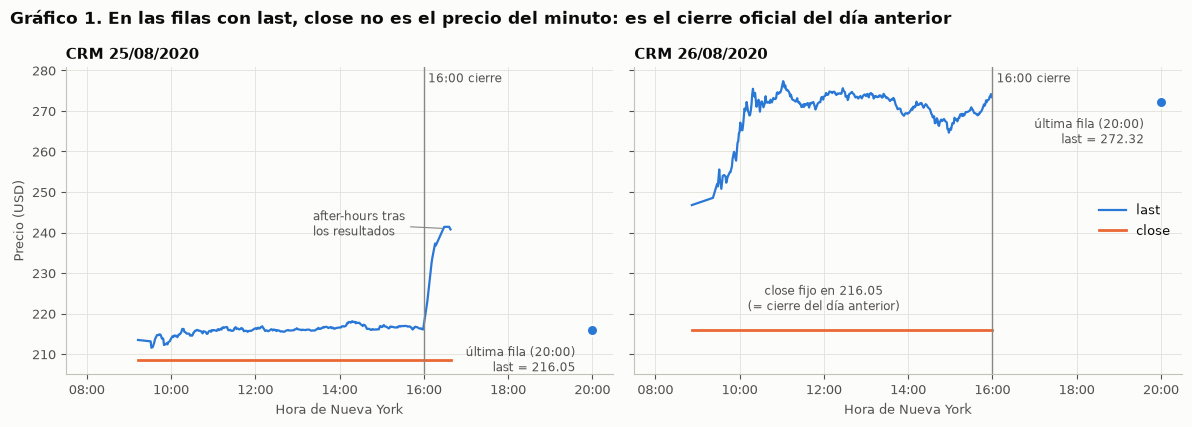

In [109]:
# Gráfico: los dos días de CRM. last sigue al precio; close se queda en el cierre del día anterior
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, dia in zip(ejes, [dia_crm_ant, dia_crm]):
    d = crm[crm["dia_ny"] == dia]
    intradia, final = d[d["minuto_ny"] < HORA_RESUMEN], d[d["minuto_ny"] >= HORA_RESUMEN]
    x = intradia["minuto_ny"] / 60
    ax.plot(x, intradia["last"], color=AZUL, lw=1.6, label="last")
    ax.plot(x, intradia["close"], color=NARANJA, lw=2, label="close")
    if len(final):
        ax.plot(final["minuto_ny"] / 60, final["last"], "o", ms=8, color=AZUL, mec=FONDO, mew=1.5)
        ax.annotate(f"última fila (20:00)\nlast = {final['last'].iloc[0]:.2f}", (20, final["last"].iloc[0]),
                    xytext=(-12, -30), textcoords="offset points", ha="right", fontsize=8.5, color=TINTA_2)
    ax.axvline(16, color=GRIS, lw=1)
    ax.text(16.1, 0.98, "16:00 cierre", transform=ax.get_xaxis_transform(), fontsize=8.5, color=TINTA_2, va="top")
    ax.set_title(f"CRM {dia:%d/%m/%Y}")
    ax.set_xticks(range(8, 21, 2), [f"{h:02d}:00" for h in range(8, 21, 2)])
    ax.set_xlim(7.5, 20.5)
    ax.set_xlabel("Hora de Nueva York")
ejes[0].set_ylabel("Precio (USD)")
ejes[0].annotate("after-hours tras\nlos resultados", (16.5, 241), xytext=(-95, -5), textcoords="offset points",
                 fontsize=8.5, color=TINTA_2, arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.8))
close_fijo = crm.loc[crm["dia_ny"] == dia_crm, "close"].iloc[0]
ejes[1].annotate(f"close fijo en {close_fijo:.2f}\n(= cierre del día anterior)", (12, close_fijo), xytext=(0, 14),
                 textcoords="offset points", fontsize=8.5, color=TINTA_2, ha="center")
ejes[1].legend(loc="center right")
fig.suptitle("Gráfico 1. En las filas con last, close no es el precio del minuto: es el cierre oficial del día anterior", x=0.01, ha="left")
plt.tight_layout()
plt.show()

# 4. Filas con last y filas sin last: dos flujos de datos distintos mezclados en el CSV

In [110]:
# Los missings de last no son aleatorios: van por días o por bloques. Clasificamos cada día según
# tenga solo filas con last, solo filas sin last o de los dos tipos.
df["tiene_last"] = df["last"].notna()
por_dia = df.groupby(["symbol", "dia_ny"])["tiene_last"].agg(["all", "any"])
por_dia["tipo"] = np.select([por_dia["all"], por_dia["any"]], ["solo con last", "mixto"], "solo sin last")
print(por_dia["tipo"].value_counts().to_string())
print(por_dia.reset_index().groupby("tipo")["dia_ny"].agg(["min", "max"]).to_string())

tipo
solo con last    4212
solo sin last    3272
mixto            2693
                     min        max
tipo                               
mixto         2020-05-29 2021-06-30
solo con last 2020-05-29 2021-02-24
solo sin last 2018-06-06 2021-03-31


In [111]:
# Miramos el primer día mixto de AMGN, alrededor de las 14:00 y de las 18:00
dia_amgn = por_dia.loc["AMGN"].query("tipo == 'mixto'").index.min()
amgn = df[(df["symbol"] == "AMGN") & (df["dia_ny"] == dia_amgn)]

print(f"\nAMGN {dia_amgn.date()}: filas CON last entre las 14:00 y las 14:20")
print(amgn.loc[amgn["tiene_last"] & amgn["minuto_ny"].between(14 * 60, 14 * 60 + 20), columnas_ver].to_string())

print(f"AMGN {dia_amgn.date()}: filas SIN last entre las 18:00 y las 18:20")
print(amgn.loc[~amgn["tiene_last"] & amgn["minuto_ny"].between(18 * 60, 18 * 60 + 20), columnas_ver].to_string())

barras = df[~df["tiene_last"]]
horario = barras.groupby(["symbol", "dia_ny"]).agg(primera=("minuto_ny", "min"), ultima=("minuto_ny", "max"),
                                                   desfase=("desfase_utc", "first"))
horario_tipico = horario.groupby("desfase")[["primera", "ultima"]].agg(lambda s: hhmm(s.mode().iloc[0]))
horario_tipico.index = horario_tipico.index.map({240: "verano (UTC-4)", 300: "invierno (UTC-5)"})
print("\nHora (NY) más frecuente de la primera y la última barra de cada día:")
print(horario_tipico.to_string())


AMGN 2020-06-15: filas CON last entre las 14:00 y las 14:20
                        hora_ny     open     high     low     last  close   volume
49147 2020-06-15 14:00:00-04:00  215.465  218.185  213.93  218.185  217.9  38496.0
49148 2020-06-15 14:05:00-04:00  215.465  219.540  213.93  219.540  217.9  45687.0
49150 2020-06-15 14:15:00-04:00  215.465  219.960  213.93  219.960  217.9  45832.0
49151 2020-06-15 14:20:00-04:00  215.465  220.525  213.93  220.525  217.9  46334.0
AMGN 2020-06-15: filas SIN last entre las 18:00 y las 18:20
                        hora_ny     open     high      low  last    close  volume
49195 2020-06-15 18:00:00-04:00  218.185  218.185  218.185   NaN  218.185     NaN
49196 2020-06-15 18:05:00-04:00  219.540  219.540  219.540   NaN  219.540     NaN
49197 2020-06-15 18:10:00-04:00  219.540  219.540  219.540   NaN  219.540     NaN
49198 2020-06-15 18:15:00-04:00  219.960  219.960  219.960   NaN  219.960     NaN
49199 2020-06-15 18:20:00-04:00  220.525  220.955  220

[H5] CSV: las filas sin last son barras (open/high/low/close de 1 a 30 minutos, sin volumen) y su hora
viene desplazada. Dónde se ve: en AMGN la barra de las "18:05" cierra en 219,54, que es el last de
las 14:05; la de las "18:15" en 219,96, el last de las 14:15... Son justo 4 horas, la diferencia
horaria entre Nueva York y UTC en verano.
- Cómo lo vimos: en el gráfico de abajo las dos líneas dibujan lo mismo, una 4 horas más tarde. Y en
todo el dataset: en verano las barras van de 13:30 a 20:00 y en invierno de 14:30 a 21:00, es decir,
la sesión real (09:30-16:00) desplazada 4 o 5 horas según el horario de Nueva York.

In [112]:
# Corrección: a las barras se les resta el desfase; las filas con last ya vienen en su hora.
df["minuto_real"] = np.where(df["tiene_last"], df["minuto_ny"], df["minuto_ny"] - df["desfase_utc"])
# Sin last y fuera de ese horario solo quedan unas pocas filas de primera hora con volumen y con el close del día
# anterior: son del otro flujo con el last vacío. Con la corrección caen fuera de la sesión y no afectan.

raras = ~df["tiene_last"] & ~df["minuto_real"].between(APERTURA, CIERRE)
print(f"Filas sin last que quedan fuera de la sesión tras corregir: {raras.sum()} | hora NY: "
      f"{df.loc[raras, 'hora_ny'].dt.hour.value_counts().sort_index().to_dict()} | con volumen: {df.loc[raras, 'volume'].notna().sum()}")

Filas sin last que quedan fuera de la sesión tras corregir: 259 | hora NY: {9: 158, 10: 96, 11: 5} | con volumen: 259


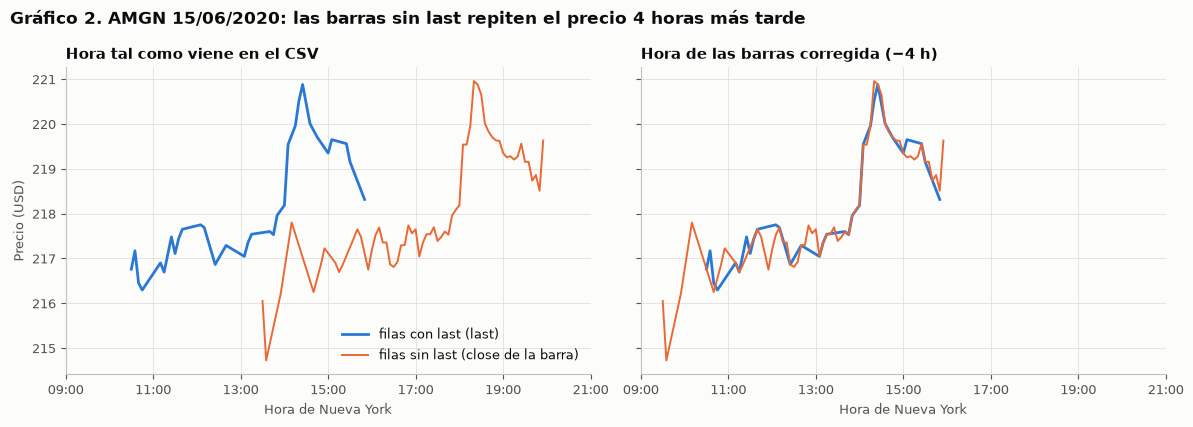

In [113]:
# Gráfico: el mismo día de AMGN antes y después de corregir la hora de las barras
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
con_last = amgn[amgn["tiene_last"] & (amgn["minuto_ny"] < HORA_RESUMEN)]
sin_last = amgn[~amgn["tiene_last"]]
for ax, corregida in zip(ejes, [False, True]):
    x_barras = (sin_last["minuto_ny"] - (sin_last["desfase_utc"] if corregida else 0)) / 60
    ax.plot(con_last["minuto_ny"] / 60, con_last["last"], color=AZUL, lw=2, label="filas con last (last)")
    ax.plot(x_barras, sin_last["close"], color=NARANJA, lw=1.4, label="filas sin last (close de la barra)")
    ax.set_title("Hora de las barras corregida (−4 h)" if corregida else "Hora tal como viene en el CSV")
    ax.set_xticks(range(9, 22, 2), [f"{h:02d}:00" for h in range(9, 22, 2)])
    ax.set_xlim(9, 21)
    ax.set_xlabel("Hora de Nueva York")
ejes[0].set_ylabel("Precio (USD)")
ejes[0].legend(loc="lower right")
fig.suptitle(f"Gráfico 2. AMGN {dia_amgn:%d/%m/%Y}: las barras sin last repiten el precio 4 horas más tarde", x=0.01, ha="left")
plt.tight_layout()
plt.show()

# 5. Descarga de Yahoo Finance (2016-2025) para las mismas 26 empresas

In [114]:
partes, splits, fallidos = [], {}, []
for ticker in empresas:
    try:
        activo = yf.Ticker(ticker)
        hist = activo.history(start=FECHA_INICIO, end=FECHA_FIN, auto_adjust=False)
        if hist.empty:
            fallidos.append(ticker)
            continue
        hist = hist.reset_index()[["Date", "Open", "High", "Low", "Close", "Volume"]]
        hist.columns = ["date", "open", "high", "low", "close", "volume"]
        hist["date"] = pd.to_datetime(hist["date"]).dt.tz_localize(None).dt.normalize()
        hist["symbol"] = ticker
        partes.append(hist)

        # Eventos de split (y spin-offs, que Yahoo registra como split) dentro de la ventana
        eventos = activo.splits
        eventos.index = eventos.index.tz_localize(None).normalize()
        splits[ticker] = eventos[(eventos.index >= FECHA_INICIO) & (eventos.index < FECHA_FIN)]
    except Exception as error:
        fallidos.append(ticker)
        print(f"{ticker}: falló la descarga -> {error}")

yahoo = pd.concat(partes, ignore_index=True)
print("Descargadas:", yahoo["symbol"].nunique(), "de", len(empresas), "| Fallidas:", fallidos)
print(yahoo.groupby("symbol")["date"].agg(["min", "max", "count"]))

Descargadas: 26 de 26 | Fallidas: []
              min        max  count
symbol                             
AAPL   2016-01-04 2025-12-31   2514
AMGN   2016-01-04 2025-12-31   2514
AXP    2016-01-04 2025-12-31   2514
BA     2016-01-04 2025-12-31   2514
CAT    2016-01-04 2025-12-31   2514
CRM    2016-01-04 2025-12-31   2514
CSCO   2016-01-04 2025-12-31   2514
CVX    2016-01-04 2025-12-31   2514
DIS    2016-01-04 2025-12-31   2514
DOW    2019-03-20 2025-12-31   1707
GS     2016-01-04 2025-12-31   2514
HD     2016-01-04 2025-12-31   2514
IBM    2016-01-04 2025-12-31   2514
INTC   2016-01-04 2025-12-31   2514
JNJ    2016-01-04 2025-12-31   2514
JPM    2016-01-04 2025-12-31   2514
KO     2016-01-04 2025-12-31   2514
MCD    2016-01-04 2025-12-31   2514
MMM    2016-01-04 2025-12-31   2514
MRK    2016-01-04 2025-12-31   2514
MSFT   2016-01-04 2025-12-31   2514
NKE    2016-01-04 2025-12-31   2514
PG     2016-01-04 2025-12-31   2514
TRV    2016-01-04 2025-12-31   2514
UNH    2016-01-04 2025-12-3

In [115]:
# Calidad de Yahoo, con los mismos controles que al CSV
print("\nNulos:", int(yahoo.isna().sum().sum()), "| Duplicados symbol+date:", int(yahoo.duplicated(["symbol", "date"]).sum()),
      "| Precios <= 0:", int((yahoo[["open", "high", "low", "close"]] <= 0).sum().sum()),
      "| Volumen 0:", int((yahoo["volume"] == 0).sum()),
      "| Velas incoherentes:", int(((yahoo["high"] < yahoo[["open", "close"]].max(axis=1))
                                    | (yahoo["low"] > yahoo[["open", "close"]].min(axis=1))).sum()))

print("Días de mercado por año (AAPL):", yahoo[yahoo["symbol"] == "AAPL"].groupby(yahoo["date"].dt.year).size().to_dict())
print("¿Hay datos el 05/12/2018 o el 09/01/2025 (bolsa cerrada)?", bool(yahoo["date"].isin(["2018-12-05", "2025-01-09"]).any()))


Nulos: 0 | Duplicados symbol+date: 0 | Precios <= 0: 0 | Volumen 0: 0 | Velas incoherentes: 0
Días de mercado por año (AAPL): {2016: 252, 2017: 251, 2018: 251, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 250}
¿Hay datos el 05/12/2018 o el 09/01/2025 (bolsa cerrada)? False


[H6] Yahoo: sin nulos, duplicados, volúmenes 0 ni velas incoherentes, y su calendario es el de la bolsa de
Nueva York, con sus cierres extraordinarios (funerales de G. H. W. Bush el 05/12/2018 y de J. Carter el
09/01/2025). 
- Cómo lo vimos: con los mismos controles que al CSV (líneas de arriba). Lo usamos como calendario
de días de mercado y como referencia para validar el CSV.

In [116]:
dow = yahoo[yahoo["symbol"] == "DOW"]
print(f"DOW: volumen mediano del 20/03 al 29/03/2019 {dow.loc[dow['date'] <= '2019-03-29', 'volume'].median():,.0f}"
      f" | en abril de 2019 {dow.loc[dow['date'].between('2019-04-01', '2019-04-30'), 'volume'].median():,.0f}")

DOW: volumen mediano del 20/03 al 29/03/2019 1,304,700 | en abril de 2019 6,681,600


[H7] Yahoo: DOW solo existe desde el 20/03/2019 (se escindió de DowDuPont; antes no cotizaba, así que no es
un hueco a imputar). Sus primeros días tienen mucho menos volumen. 

# 6. La fila resumen del final del día y el close del día siguiente: el cierre oficial

In [117]:
calendario = yahoo[["symbol", "date"]].sort_values(["symbol", "date"]).reset_index(drop=True)
calendario["dia_anterior"] = calendario.groupby("symbol")["date"].shift()

df["es_resumen"] = df["tiene_last"] & (df["minuto_ny"] >= HORA_RESUMEN)
resumen = df[df["es_resumen"]].drop(columns="date").rename(columns={"dia_ny": "date"})
es_ultima = df["date"] == df.groupby(["symbol", "dia_ny"])["date"].transform("max")

print("Filas con last a partir de las 20:00:", len(resumen), "| hora NY:",
      resumen["hora_ny"].dt.strftime("%H:%M").value_counts().to_dict())
print("¿Es siempre la última fila de su día?", bool(es_ultima[df["es_resumen"]].all()),
      "| ¿Como mucho una por día?", bool(resumen.groupby(["symbol", "date"]).size().max() == 1))

# close de las filas con last = cierre oficial del día de mercado ANTERIOR ([H2]); se lo asignamos a ese día
cierre_oficial = (
    df[df["tiene_last"] & ~df["es_resumen"]]
    .groupby(["symbol", "dia_ny"])["close"].agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
    .rename("cierre_oficial").reset_index().rename(columns={"dia_ny": "date"})
    .merge(calendario, on=["symbol", "date"])
    .dropna(subset=["dia_anterior", "cierre_oficial"])
    [["symbol", "dia_anterior", "cierre_oficial"]].rename(columns={"dia_anterior": "date"})
)

comp = resumen[["symbol", "date", "last"]].merge(cierre_oficial, on=["symbol", "date"])
coincide = (comp["last"] - comp["cierre_oficial"]).abs() < 0.005
print(f"\nFilas resumen con día siguiente en el CSV: {len(comp)} | last == close del día siguiente: {coincide.mean():.2%}")

# Donde no coinciden, ¿cuál es el bueno? Lo miramos contra Yahoo (son empresas sin splits en esas fechas)
distintos = comp[~coincide].merge(yahoo[["symbol", "date", "close"]], on=["symbol", "date"])
print(f"No coinciden: {len(distintos)} {distintos['symbol'].value_counts().to_dict()} | meses: "
      f"{distintos['date'].dt.strftime('%m/%Y').unique().tolist()}")
print(distintos.head(5).to_string())
print(f"  igual a Yahoo: el last del resumen en {(distintos['last'] - distintos['close']).abs().lt(0.005).sum()} casos,"
      f" el close del día siguiente en {(distintos['cierre_oficial'] - distintos['close']).abs().lt(0.005).sum()}")

Filas con last a partir de las 20:00: 4692 | hora NY: {'20:00': 2598, '21:00': 2094}
¿Es siempre la última fila de su día? True | ¿Como mucho una por día? True

Filas resumen con día siguiente en el CSV: 4649 | last == close del día siguiente: 99.44%
No coinciden: 26 {'DIS': 12, 'CVX': 9, 'AXP': 5} | meses: ['07/2020']
  symbol       date   last  cierre_oficial      close
0    AXP 2020-07-06  96.57           96.58  96.580002
1    AXP 2020-07-08  92.89           92.90  92.900002
2    AXP 2020-07-09  90.60           90.57  90.570000
3    AXP 2020-07-20  93.97           94.00  94.000000
4    AXP 2020-07-21  96.32           96.33  96.330002
  igual a Yahoo: el last del resumen en 0 casos, el close del día siguiente en 26


[H8] CSV: la última fila de cada día con last (20:00 en verano, 21:00 en invierno) es un RESUMEN del día:
su last es el cierre oficial, el mismo valor que repite close en todas las filas del día siguiente.
- Dónde se ve: CRM 25/08/2020 a las 20:00 -> last = 216,05 = close de todo el 26/08 (paso 3).
- Cómo lo vimos: comparando en todos los días el last de esa fila con el close del día de mercado siguiente.

[H9] CSV: en esos días el last del resumen se desvía 1-6 céntimos y el close del día siguiente coincide con
Yahoo. Dónde se ve: AXP 09/07/2020 -> resumen 90,60, close del día siguiente 90,57, Yahoo 90,57.
- Cómo lo vimos: con la tabla de arriba. Por eso, para el cierre, primero el close del día siguiente y, si no lo hay, el last del resumen.

In [118]:
# ¿La fila resumen es siempre una vela normal? Comprobamos su coherencia (high >= open, cierre; low <= open, cierre)
incoherente = (resumen["high"] < resumen[["open", "last"]].max(axis=1)) | (resumen["low"] > resumen[["open", "last"]].min(axis=1))
degenerada = (resumen["open"] == resumen["high"]) & (resumen["high"] == resumen["low"])
print(f"\nFilas resumen incoherentes: {incoherente.sum()} (todas con open = high = low: {bool(degenerada[incoherente].all())})"
      f" | filas resumen con open = high = low: {degenerada.sum()}")
print(resumen.loc[degenerada, ["symbol", "date", "open", "high", "low", "last", "volume"]].to_string())
# [H10] CSV: 9 filas resumen (AAPL e INTC entre el 29/05 y el 08/06/2020) traen open = high = low: esa vela
#   está rota (su last sí es el cierre oficial). Cómo lo vimos: al comprobar la coherencia de las filas resumen
#   salen 8 incoherentes y todas tienen open = high = low. En esos días open/high/low saldrán de la sesión.

# Volumen de la fila resumen frente al acumulado de las filas anteriores del mismo día (se retoma en el paso 10)
vol_antes = df[df["tiene_last"] & ~df["es_resumen"]].groupby(["symbol", "dia_ny"])["volume"].max()
vol_antes.index = vol_antes.index.set_names(["symbol", "date"])
print(f"Volumen de la fila resumen / volumen acumulado antes de ella: mediana "
      f"{(resumen.set_index(['symbol', 'date'])['volume'] / vol_antes).median():.1f}")


Filas resumen incoherentes: 8 (todas con open = high = low: True) | filas resumen con open = high = low: 9
        symbol       date     open     high      low    last      volume
21489     AAPL 2020-05-29  318.990  318.990  318.990  317.94  38399532.0
21571     AAPL 2020-06-01  321.775  321.775  321.775  321.85  20254653.0
21880     AAPL 2020-06-04  322.320  322.320  322.320  322.32  21316854.0
22005     AAPL 2020-06-05  331.480  331.480  331.480  331.50  33592989.0
1306767   INTC 2020-05-29   63.035   63.035   63.035   62.93  33395738.0
1307159   INTC 2020-06-01   61.840   61.840   61.840   61.86  14329044.0
1308703   INTC 2020-06-04   62.960   62.960   62.960   62.97  21578600.0
1309376   INTC 2020-06-05   64.275   64.275   64.275   64.34  26635504.0
1309936   INTC 2020-06-08   63.665   63.665   63.665   63.67  21175383.0
Volumen de la fila resumen / volumen acumulado antes de ella: mediana 33.3



% de días (empresa-día) de cada mes con cada tipo de fila (antes de mayo de 2020: 100 % barras):
         barras  con_last  resumen
dia_ny                            
2020-05    88.1      15.4     15.4
2020-06    25.3      91.1     83.9
2020-07     6.8     100.0     96.7
2020-08    12.3     100.0     97.4
2020-09     9.0     100.0     92.7
2020-10    37.4      92.5     80.4
2020-11     5.8     100.0     99.8
2020-12     7.2     100.0     99.7
2021-01     1.4     100.0     99.6
2021-02    11.7     100.0     99.0
2021-03   100.0      84.3     18.7
2021-04   100.0     100.0      0.9
2021-05   100.0     100.0      0.2
2021-06   100.0     100.0      0.0


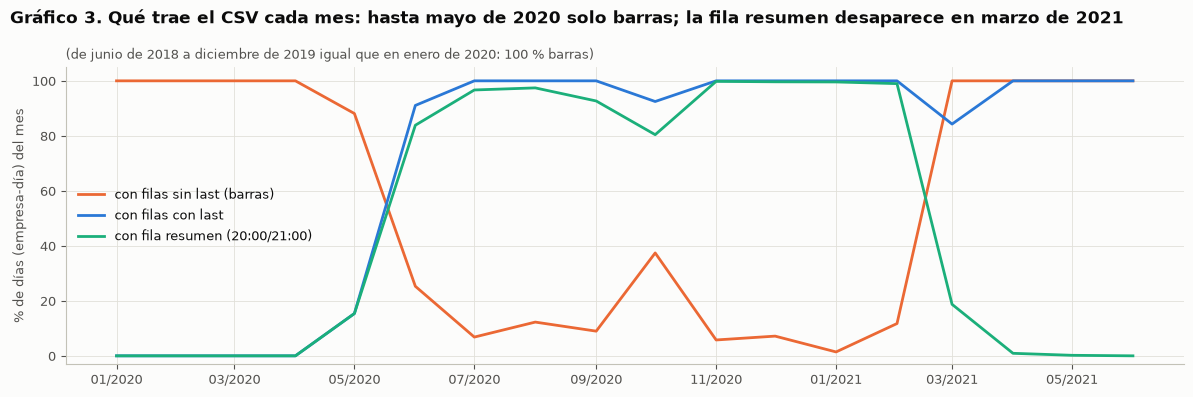

In [119]:
# ¿Qué días tienen fila resumen? % de días (empresa-día) de cada mes con cada tipo de fila
tipo_dia = df.groupby(["symbol", "dia_ny"]).agg(barras=("tiene_last", lambda s: (~s).any()),
                                                con_last=("tiene_last", "any"), resumen=("es_resumen", "any"))
pct_mes = tipo_dia.groupby(tipo_dia.index.get_level_values("dia_ny").to_period("M")).mean() * 100
print("\n% de días (empresa-día) de cada mes con cada tipo de fila (antes de mayo de 2020: 100 % barras):")
print(pct_mes.loc["2020-05":].round(1).to_string())

# [H11] CSV: la fila resumen está en el 80-100 % de los días de junio de 2020 a febrero de 2021 y desaparece
#   desde marzo de 2021 (19 % en marzo, ~0 % después). Cómo lo vimos: con esta tabla y el gráfico de abajo.

fig, ax = plt.subplots(figsize=(12, 4))
tramo_graf = pct_mes.loc["2020-01":]
x = tramo_graf.index.to_timestamp()
ax.plot(x, tramo_graf["barras"], color=NARANJA, label="con filas sin last (barras)")
ax.plot(x, tramo_graf["con_last"], color=AZUL, label="con filas con last")
ax.plot(x, tramo_graf["resumen"], color=VERDE, label="con fila resumen (20:00/21:00)")
ax.set_ylabel("% de días (empresa-día) del mes")
ax.set_ylim(-3, 105)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.legend(loc="center left")
fig.suptitle("Gráfico 3. Qué trae el CSV cada mes: hasta mayo de 2020 solo barras; la fila resumen desaparece en marzo de 2021",
             x=0.01, ha="left")
ax.set_title("(de junio de 2018 a diciembre de 2019 igual que en enero de 2020: 100 % barras)", fontweight="normal",
             color=TINTA_2, fontsize=9)
plt.tight_layout()
plt.show()

# 7. Vela diaria del CSV

- close: cierre oficial -> el close del día siguiente y, si no hay, el last de la fila resumen; si no hay
ninguno de los dos, el último precio de la sesión (last en las filas con last, close en las barras)
- open/high/low y volumen: los de la fila resumen; si no hay resumen (o es una vela rota, [H10]),
open/high/low salen de la sesión real (09:30-16:00, barras con la hora corregida)
- día incompleto (open/high/low de una sesión cortada, o cierre tomado antes de las 15:30) -> se marca

In [120]:
vela_resumen = resumen.groupby(["symbol", "date"]).agg(
    open_res=("open", "last"), high_res=("high", "last"), low_res=("low", "last"),
    close_res=("last", "last"), volume_res=("volume", "last"))

sesion = df[df["minuto_real"].between(APERTURA, CIERRE)].sort_values(["symbol", "dia_ny", "minuto_real"])
sesion = sesion.assign(precio=np.where(sesion["tiene_last"], sesion["last"], sesion["close"]))
con_precio = sesion.dropna(subset=["precio"]).groupby(["symbol", "dia_ny"])
g = sesion.groupby(["symbol", "dia_ny"])
vela_sesion = pd.DataFrame({
    "open": g["open"].first(), "high": g["high"].max(), "low": g["low"].min(),
    "volume": g["volume"].max(),                  # acumulado -> el máximo es el total (se revisa en el paso 10)
    "inicio": g["minuto_real"].min(), "fin": g["minuto_real"].max(),
    "precio_sesion": con_precio["precio"].last(), "hora_precio": con_precio["minuto_real"].last(),
})
vela_sesion.index = vela_sesion.index.set_names(["symbol", "date"])

In [121]:
diario = (
    df.groupby(["symbol", "dia_ny"]).size().rename("filas").rename_axis(["symbol", "date"]).to_frame()
    .join(vela_resumen).join(vela_sesion)
    .reset_index()
    .merge(cierre_oficial, on=["symbol", "date"], how="left")
)
diario["tiene_resumen"] = diario["close_res"].notna()
ohl_resumen = diario["tiene_resumen"] & ~((diario["open_res"] == diario["high_res"]) & (diario["high_res"] == diario["low_res"]))

diario["origen_close"] = np.select(
    [diario["cierre_oficial"].notna(), diario["tiene_resumen"], diario["precio_sesion"].notna()],
    ["close del día siguiente", "fila resumen", "último precio de la sesión"], default="sin cierre")

diario["close"] = diario["cierre_oficial"].fillna(diario["close_res"]).fillna(diario["precio_sesion"])

for col in ["open", "high", "low"]:
    diario[col] = np.where(ohl_resumen, diario[f"{col}_res"], diario[col])
diario["volume"] = np.where(diario["tiene_resumen"], diario["volume_res"], diario["volume"])
diario["origen_ohl"] = np.where(ohl_resumen, "fila resumen", "sesión")

sesion_cortada = diario["inicio"].isna() | (diario["inicio"] > INICIO_MAXIMO) | (diario["fin"] < FIN_MINIMO)
cierre_temprano = (diario["origen_close"] == "último precio de la sesión") & (diario["hora_precio"] < FIN_MINIMO)
diario["incompleto"] = (~ohl_resumen & sesion_cortada) | cierre_temprano

In [122]:
print(diario.shape)
print(pd.crosstab(diario["origen_close"], diario["origen_ohl"], margins=True, margins_name="total"))
print("\nDías sin cierre:", int((diario["origen_close"] == "sin cierre").sum()))
print(diario.loc[diario["origen_close"] == "sin cierre", "date"].dt.date.value_counts().sort_index().to_string())

def hhmm(minutos):
    if pd.isna(minutos) or minutos == "-":
        return "-"
    return f"{int(minutos) // 60:02d}:{int(minutos) % 60:02d}"

incompletos = diario[diario["incompleto"]]
print(f"\nDías incompletos: {len(incompletos)}")
print(incompletos.groupby("date").agg(
    empresas=("symbol", "size"),
    primera_fila_max=("inicio", lambda s: hhmm(s.max())),
    ultima_fila_min=("fin", lambda s: hhmm(s.min())),
    ultimo_precio_max=("hora_precio", lambda s: hhmm(s.max()) if s.notna().any() else "-")).to_string())

diario = diario[["symbol", "date", "open", "high", "low", "close", "volume",
                 "origen_close", "origen_ohl", "tiene_resumen", "incompleto"]]
print("\n", diario[(diario["symbol"] == "CRM") & diario["date"].between("2020-08-24", "2020-08-27")].to_string())

(10177, 22)
origen_ohl                  fila resumen  sesión  total
origen_close                                           
close del día siguiente             4640    2178   6818
fila resumen                          43       0     43
sin cierre                             0      52     52
último precio de la sesión             0    3264   3264
total                               4683    5494  10177

Días sin cierre: 52
date
2021-03-11    26
2021-03-30    26

Días incompletos: 50
            empresas primera_fila_max ultima_fila_min ultimo_precio_max
date                                                                   
2020-06-02        20            10:51           12:24             12:28
2020-06-04         1            11:00           15:55             15:55
2020-09-16         2            10:45           15:55             15:59
2020-12-18         1            10:11           15:58             15:58
2021-03-29        26            09:30           16:00             11:18

      sym

[H12] CSV: hay días incompletos, en los que los datos se cortan a media sesión y no hay fila resumen.
- Dónde se ve: 02/06/2020 (20 empresas con datos solo hasta las 12:24-12:28) y 29/03/2021 (las 26: la última fila con last es como muy tarde de las 11:18 y las barras siguen hasta las 16:00, pero sin close).
- Cómo lo vimos: calculando la hora de la primera y la última fila de la sesión de cada día; y porque al
- validar contra Yahoo (paso 9) esos días salen con errores en el cierre de hasta el 1,7 %.

# 8. Splits: ¿qué fuente viene ajustada?

In [123]:
def factor_split(ticker, fecha):
    """Producto de los factores de split posteriores a la fecha (1 si no hay ninguno)."""
    eventos = splits.get(ticker)
    if eventos is None or eventos.empty:
        return 1.0
    posteriores = eventos[eventos.index > fecha]
    return float(np.prod(posteriores.values)) if len(posteriores) else 1.0


print("Eventos que Yahoo registra como split:")
for ticker, eventos in splits.items():
    for fecha, ratio in eventos.items():
        print(f"  {ticker:5s} {fecha.date()}  factor {ratio:g}")

# Si Yahoo está ajustado y el CSV no, close_CSV / close_Yahoo = factor de los splits posteriores a cada fecha.
# Para el volumen usamos solo los días con fila resumen (el único volumen consolidado del CSV, paso 10).
comparacion = diario.merge(
    yahoo[["symbol", "date", "close", "volume"]].rename(columns={"close": "close_yahoo", "volume": "volume_yahoo"}),
    on=["symbol", "date"], how="inner",
).dropna(subset=["close"])
comparacion["factor"] = [factor_split(t, f) for t, f in zip(comparacion["symbol"], comparacion["date"])]
comparacion["cociente_close"] = comparacion["close"] / comparacion["close_yahoo"]
comparacion["cociente_volume"] = (comparacion["volume"] / comparacion["volume_yahoo"]).where(comparacion["tiene_resumen"])

con_eventos = [t for t, ev in splits.items() if not ev.empty]
print(
    comparacion[comparacion["symbol"].isin(con_eventos)]
    .groupby(["symbol", "factor"])
    .agg(dias=("cociente_close", "size"),
         cociente_close=("cociente_close", "median"),
         cociente_volume=("cociente_volume", "median"))
    .round(3)
)

Eventos que Yahoo registra como split:
  AAPL  2020-08-31  factor 4
  IBM   2021-11-04  factor 1.046
  MMM   2024-04-01  factor 1.196
  MRK   2021-06-03  factor 1.048
               dias  cociente_close  cociente_volume
symbol factor                                       
AAPL   1.000    208           1.000            1.000
       4.000    562           4.000            0.246
IBM    1.046    269           1.046            0.956
MMM    1.196    269           1.196            0.836
MRK    1.000     20           1.000              NaN
       1.048    249           1.048            0.954


[H13] CSV: los precios vienen sin ajustar por splits (tal como cotizaron). Dónde se ve: AAPL pasa de ~500 $ a ~125 $ el 31/08/2020 (gráfico de abajo), una caída del 75 % que no existió: fue el split 4:1.
[H14] Yahoo: su Close ya viene ajustado por splits aunque se pida auto_adjust=False (ese parámetro solo decide
si se descuentan los dividendos) y trata los spin-offs como splits: IBM 1,046 (Kyndryl, 2021), MMM 1,196
(Solventum, 2024) y MRK 1,048 (Organon, 2021). El volumen lleva el ajuste inverso.
- Cómo lo vimos: con la tabla (el cociente CSV / Yahoo es justo el factor de los eventos posteriores a cada fecha) y con el gráfico de AAPL alrededor de su split 4:1.

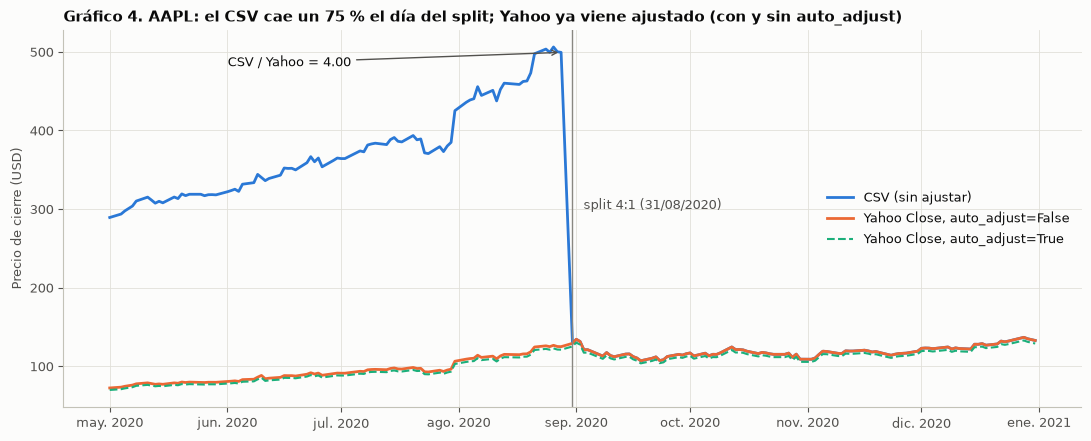

In [124]:
FECHA_SPLIT_AAPL = pd.Timestamp("2020-08-31")
aapl_csv = diario[diario["symbol"] == "AAPL"].set_index("date")["close"].loc["2020-05-01":"2020-12-31"]
aapl_sin_auto = yf.Ticker("AAPL").history(start="2020-05-01", end="2021-01-01", auto_adjust=False)["Close"]
aapl_con_auto = yf.Ticker("AAPL").history(start="2020-05-01", end="2021-01-01", auto_adjust=True)["Close"]
for serie in (aapl_sin_auto, aapl_con_auto):
    serie.index = serie.index.tz_localize(None).normalize()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(aapl_csv, color=AZUL, lw=2, label="CSV (sin ajustar)")
ax.plot(aapl_sin_auto, color=NARANJA, lw=2, label="Yahoo Close, auto_adjust=False")
ax.plot(aapl_con_auto, color=VERDE, lw=1.5, ls="--", label="Yahoo Close, auto_adjust=True")
ax.axvline(FECHA_SPLIT_AAPL, color=GRIS, lw=1)
ax.annotate("split 4:1 (31/08/2020)", xy=(FECHA_SPLIT_AAPL, 300), xytext=(8, 0),
            textcoords="offset points", color=TINTA_2, fontsize=9)
dia_antes = aapl_csv.loc[:FECHA_SPLIT_AAPL - pd.Timedelta(days=1)].index.max()
ax.annotate(f"CSV / Yahoo = {aapl_csv[dia_antes] / aapl_sin_auto[dia_antes]:.2f}",
            xy=(dia_antes, aapl_csv[dia_antes]), xytext=(-240, -10), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color=TINTA_2), fontsize=9)
ax.set_title("Gráfico 4. AAPL: el CSV cae un 75 % el día del split; Yahoo ya viene ajustado (con y sin auto_adjust)")
ax.set_ylabel("Precio de cierre (USD)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

In [125]:
# Ajuste del CSV a la escala de Yahoo: precios / factor, volumen * factor
diario["factor"] = [factor_split(t, f) for t, f in zip(diario["symbol"], diario["date"])]
for col in ["open", "high", "low", "close"]:
    diario[col] = diario[col] / diario["factor"]
diario["volume"] = diario["volume"] * diario["factor"]
print("\nFilas del CSV ajustadas:", int((diario["factor"] != 1).sum()))
print(diario.loc[diario["factor"] != 1].groupby("symbol")["factor"].agg(["min", "max", "count"]))
diario = diario.drop(columns=["factor"])


Filas del CSV ajustadas: 1374
          min    max  count
symbol                     
AAPL    4.000  4.000    581
IBM     1.046  1.046    271
MMM     1.196  1.196    271
MRK     1.048  1.048    251


# 9. Validación de la vela del CSV contra Yahoo 

In [126]:
validacion = diario.merge(yahoo[["symbol", "date", "open", "high", "low", "close"]], on=["symbol", "date"],
                          how="inner", suffixes=("", "_yahoo")).dropna(subset=["close"])
for col in ["open", "high", "low", "close"]:
    validacion[f"error_{col}"] = (validacion[col] / validacion[f"{col}_yahoo"] - 1) * 100


def resumen_error(e):
    e = e.abs()
    return pd.Series({"dias": len(e), "error_medio_%": round(e.mean(), 4), "mediana_%": round(e.median(), 4),
                      "max_%": round(e.max(), 3), "dias_>1%": int((e > 1).sum()), "dias_>5%": int((e > 5).sum())})


print("Error del cierre del CSV frente a Yahoo, según de dónde sale:")
print(validacion.groupby(np.where(validacion["incompleto"], "(día incompleto)", validacion["origen_close"]))["error_close"]
      .apply(resumen_error).unstack().to_string())

Error del cierre del CSV frente a Yahoo, según de dónde sale:
                              dias  error_medio_%  mediana_%  max_%  dias_>1%  dias_>5%
(día incompleto)              50.0         0.5980     0.5452  1.730       9.0       0.0
close del día siguiente     6814.0         0.0000     0.0000  0.073       0.0       0.0
fila resumen                  43.0         0.0000     0.0000  0.000       0.0       0.0
último precio de la sesión  3104.0         0.0323     0.0126  4.537       6.0       0.0


[H15] Validación del cierre oficial del CSV:
Al comparar los precios de cierre del CSV frente a Yahoo Finance, se observa que el cierre oficial extraído de la jerarquía principal (close del día siguiente o fila resumen) muestra una mediana de error del 0,00% (con un error medio muy bajo condicionado por valores atípicos aislados), lo que confirma que estos registros representan fielmente el cierre oficial de la bolsa (respaldando los hallazgos [H2] y [H8]).

Por otro lado, los datos obtenidos mediante el último precio de la sesión (plan B para los años antiguos) se quedan muy cerca de la referencia (mediana próxima al 0,02%), aunque presentan una mayor dispersión debido a que el proveedor original (IEX) no gestiona la subasta de cierre nacional consolidada (Closing Auction), una limitación menor que se asume por tratarse de un desvío milimétrico que no afecta al análisis general.

In [127]:
# ¿Merece la pena frente a la regla que usábamos al principio (último last hasta las 16:00 y, sin last, último
# close del día)? La reconstruimos y la comparamos con Yahoo en los mismos términos.
aux = df[["symbol", "dia_ny", "minuto_ny", "open", "high", "low", "last", "close"]].assign(
    last_sesion=df["last"].where(df["minuto_ny"] <= CIERRE))
regla_inicial = aux.groupby(["symbol", "dia_ny"]).agg(open=("open", "first"), high=("high", "max"), low=("low", "min"),
                                                      last_sesion=("last_sesion", "last"), last_dia=("last", "last"),
                                                      close_barra=("close", "last"), n_last=("last", "count"))
regla_inicial["close"] = np.where(regla_inicial["n_last"] > 0, regla_inicial["last_sesion"].fillna(regla_inicial["last_dia"]),
                                  regla_inicial["close_barra"])
regla_inicial = regla_inicial.reset_index().rename(columns={"dia_ny": "date"})[["symbol", "date", "open", "high", "low", "close"]]
factores = [factor_split(t, f) for t, f in zip(regla_inicial["symbol"], regla_inicial["date"])]
for col in ["open", "high", "low", "close"]:
    regla_inicial[col] = regla_inicial[col] / factores
val_inicial = regla_inicial.merge(yahoo[["symbol", "date", "open", "high", "low", "close"]], on=["symbol", "date"],
                                  suffixes=("", "_yahoo")).dropna()
for col in ["open", "high", "low", "close"]:
    val_inicial[f"error_{col}"] = (val_inicial[col] / val_inicial[f"{col}_yahoo"] - 1) * 100
completos = validacion[~validacion["incompleto"]]
print("\nComparación de reglas para el cierre:")
print(pd.DataFrame({"regla inicial (último last hasta las 16:00)": resumen_error(val_inicial["error_close"]),
                    "vela oficial (días completos)": resumen_error(completos["error_close"])}).T.to_string())
print("Error máximo de open/high/low con la regla inicial (primero/máximo/mínimo del día entero): "
      + " | ".join(f"{col} {val_inicial[f'error_{col}'].abs().max():.1f} %" for col in ["open", "high", "low"]))


# Efecto en la volatilidad del tramo del CSV (jun 2020 - jun 2021): serie de Yahoo con el cierre del CSV donde lo
# hay, según cada regla. Yahoo sirve de referencia porque coincide con el cierre oficial ([H15]).
def sigma_anual(cierres):
    cierres = cierres.sort_values(["symbol", "date"])
    retornos = np.log(cierres["close"]).groupby(cierres["symbol"]).diff()
    return retornos.groupby(cierres["symbol"]).std() * np.sqrt(252) * 100


tramo = yahoo.loc[yahoo["date"].between("2020-06-01", "2021-06-30"), ["symbol", "date", "close"]]
sigmas = {"Yahoo": sigma_anual(tramo)}
for nombre, cierres_csv in [("regla inicial", regla_inicial[["symbol", "date", "close"]]),
                            ("vela oficial", completos[["symbol", "date", "close"]])]:
    serie = tramo.merge(cierres_csv.dropna(), on=["symbol", "date"], how="left", suffixes=("_yahoo", ""))
    serie["close"] = serie["close"].fillna(serie["close_yahoo"])
    sigmas[nombre] = sigma_anual(serie)
sigmas = pd.DataFrame(sigmas)
for nombre in ["regla inicial", "vela oficial"]:
    dif = (sigmas[nombre] - sigmas["Yahoo"]).abs()
    print(f"σ anual jun 2020-jun 2021, {nombre:13s}: diferencia con Yahoo media {dif.mean():.3f} pp"
          f" | máxima {dif.max():.3f} pp ({dif.idxmax()})")


Comparación de reglas para el cierre:
                                               dias  error_medio_%  mediana_%  max_%  dias_>1%  dias_>5%
regla inicial (último last hasta las 16:00)  9969.0         0.0792     0.0388  4.537      48.0       0.0
vela oficial (días completos)                9961.0         0.0101     0.0000  4.537       6.0       0.0
Error máximo de open/high/low con la regla inicial (primero/máximo/mínimo del día entero): open 17.8 % | high 10.6 % | low 9.7 %
σ anual jun 2020-jun 2021, regla inicial: diferencia con Yahoo media 0.203 pp | máxima 0.730 pp (DOW)
σ anual jun 2020-jun 2021, vela oficial : diferencia con Yahoo media 0.034 pp | máxima 0.408 pp (GS)


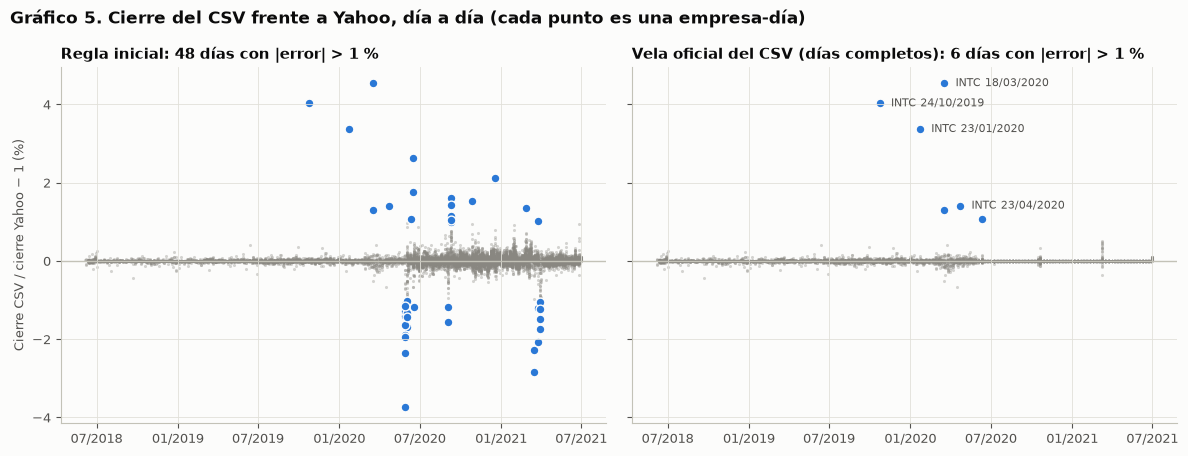


Días completos con |error del cierre| > 1 %:
     symbol       date                origen_close   close  close_yahoo  error_close
5484   INTC 2020-03-18  último precio de la sesión   49.77       47.610        4.537
5385   INTC 2019-10-24  último precio de la sesión   54.33       52.230        4.021
5446   INTC 2020-01-23  último precio de la sesión   65.45       63.320        3.364
5509   INTC 2020-04-23  último precio de la sesión   59.87       59.040        1.406
448    AAPL 2020-03-18  último precio de la sesión   62.47       61.667        1.301
4229     GS 2020-06-11  último precio de la sesión  196.22      194.130        1.077
Barras de las 16:00 que son un único precio (open = high = low = close): 98.8%
σ anual de GS jun 2020-jun 2021: Yahoo 30.93 % | vela oficial 30.52 % | vela oficial sin su 11/06/2020 30.92 %


In [128]:
# Gráfico: error del cierre de cada día con las dos reglas (así localizamos los días raros)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (titulo, datos) in zip(ejes, [("Regla inicial", val_inicial), ("Vela oficial del CSV (días completos)", completos)]):
    grande = datos["error_close"].abs() > 1
    ax.scatter(datos.loc[~grande, "date"], datos.loc[~grande, "error_close"], s=5, color=GRIS, alpha=0.35, lw=0)
    ax.scatter(datos.loc[grande, "date"], datos.loc[grande, "error_close"], s=40, color=AZUL, edgecolor=FONDO, lw=1)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_title(f"{titulo}: {int(grande.sum())} días con |error| > 1 %")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ejes[0].set_ylabel("Cierre CSV / cierre Yahoo − 1 (%)")
for _, fila in completos.loc[completos["error_close"].abs().nlargest(4).index].iterrows():
    ejes[1].annotate(f"{fila['symbol']} {fila['date']:%d/%m/%Y}", (fila["date"], fila["error_close"]),
                     xytext=(8, 0), textcoords="offset points", fontsize=8, color=TINTA_2, va="center")
fig.suptitle("Gráfico 5. Cierre del CSV frente a Yahoo, día a día (cada punto es una empresa-día)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

# Los días completos que siguen por encima del 1 %, uno a uno
print("\nDías completos con |error del cierre| > 1 %:")
print(completos.loc[completos["error_close"].abs() > 1, ["symbol", "date", "origen_close", "close", "close_yahoo", "error_close"]]
      .sort_values("error_close", key=abs, ascending=False).round({"close": 3, "close_yahoo": 3, "error_close": 3}).to_string())
barra_16 = df[~df["tiene_last"] & df["close"].notna() & (df["minuto_real"] == CIERRE)]
print(f"Barras de las 16:00 que son un único precio (open = high = low = close): "
      f"{((barra_16['open'] == barra_16['close']) & (barra_16['high'] == barra_16['low'])).mean():.1%}")

# ¿Cuánto pesan en σ? GS es la empresa que más se desvía con la vela oficial (arriba). Quitando solo su
# 11/06/2020 (ese día con el cierre de Yahoo):
sin_gs = completos.loc[~((completos["symbol"] == "GS") & (completos["date"] == "2020-06-11")), ["symbol", "date", "close"]]
serie = tramo.merge(sin_gs, on=["symbol", "date"], how="left", suffixes=("_yahoo", ""))
serie["close"] = serie["close"].fillna(serie["close_yahoo"])
print(f"σ anual de GS jun 2020-jun 2021: Yahoo {sigmas.loc['GS', 'Yahoo']:.2f} % | vela oficial "
      f"{sigmas.loc['GS', 'vela oficial']:.2f} % | vela oficial sin su 11/06/2020 {sigma_anual(serie).loc['GS']:.2f} %")

[H16] CSV: los 6 son días en los que el cierre sale de las barras (sin cierre oficial) y la última barra, la de
las 16:00 (casi siempre un único precio), no es el cierre oficial:
- días de resultados de INTC publicados tras el cierre (24/10/2019, 23/01/2020 y 23/04/2020): la barra de las
16:00 ya trae el precio after-hours. El 24/10/2019 ese mismo precio (54,33) aparece incluso en la barra de
las 15:00, antes de publicarse los resultados: son precios fuera de su sitio.
- 18/03/2020, INTC y AAPL: ticks erróneos. En INTC se repite 49,77 como high y close de barras que abren
entre 45,5 y 46,5 (el cierre oficial fue 47,61).
- GS 11/06/2020: la barra de las 16:00 es un precio aislado (196,22) y la anterior cierra en 194,18 (oficial 194,13).
- Cómo lo vimos: con el gráfico de arriba (los puntos azules que quedan a la derecha) y mirando las barras de esos
días (gráfico de abajo). Decisión del equipo: se mantienen (el CSV manda) y quedan como pendientes.

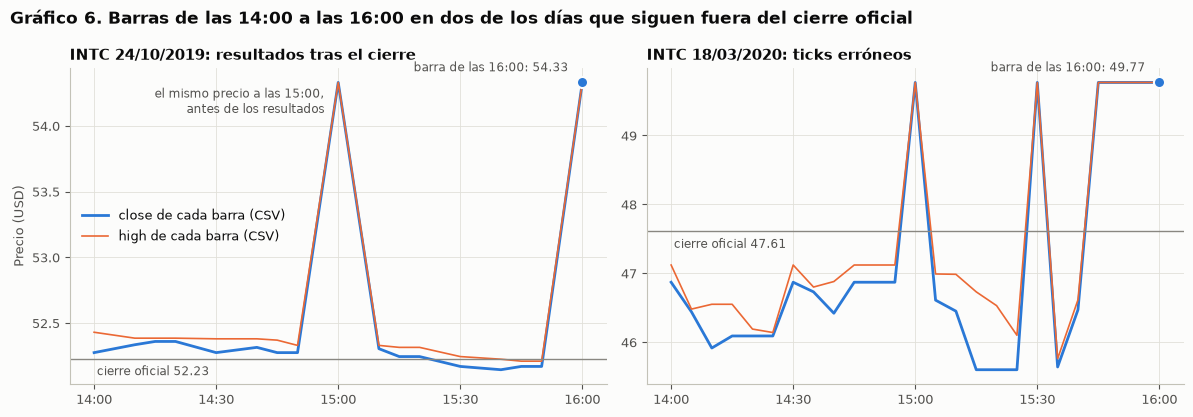


Error de open/high/low frente a Yahoo (días completos), según de dónde salen:
  open: {'fila resumen': {'dias': 4683.0, 'error_medio_%': 0.0002, 'mediana_%': 0.0, 'dias_>1%': 0.0}, 'sesión': {'dias': 5278.0, 'error_medio_%': 0.2019, 'mediana_%': 0.0923, 'dias_>1%': 128.0}}
  high: {'fila resumen': {'dias': 4683.0, 'error_medio_%': 0.0008, 'mediana_%': 0.0, 'dias_>1%': 1.0}, 'sesión': {'dias': 5278.0, 'error_medio_%': 0.0554, 'mediana_%': 0.0134, 'dias_>1%': 31.0}}
  low: {'fila resumen': {'dias': 4683.0, 'error_medio_%': 0.0003, 'mediana_%': 0.0, 'dias_>1%': 0.0}, 'sesión': {'dias': 5278.0, 'error_medio_%': 0.0536, 'mediana_%': 0.0156, 'dias_>1%': 21.0}}


In [129]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (simbolo, dia, titulo) in zip(ejes, [("INTC", "2019-10-24", "resultados tras el cierre"),
                                             ("INTC", "2020-03-18", "ticks erróneos")]):
    b = df[(df["symbol"] == simbolo) & (df["dia_ny"] == dia) & ~df["tiene_last"]].sort_values("minuto_real")
    b = b[b["minuto_real"] >= 14 * 60]
    oficial = yahoo.loc[(yahoo["symbol"] == simbolo) & (yahoo["date"] == dia), "close"].iloc[0]
    ax.plot(b["minuto_real"] / 60, b["close"], color=AZUL, lw=2, label="close de cada barra (CSV)")
    ax.plot(b["minuto_real"] / 60, b["high"], color=NARANJA, lw=1.2, label="high de cada barra (CSV)")
    ax.axhline(oficial, color=GRIS, lw=1)
    ax.annotate(f"cierre oficial {oficial:.2f}", (14, oficial), xytext=(2, -12), textcoords="offset points",
                fontsize=8.5, color=TINTA_2)
    ultima = b.iloc[-1]
    ax.plot(ultima["minuto_real"] / 60, ultima["close"], "o", ms=8, color=AZUL, mec=FONDO, mew=1.5)
    ax.annotate(f"barra de las 16:00: {ultima['close']:.2f}", (16, ultima["close"]), xytext=(-10, 8),
                textcoords="offset points", ha="right", fontsize=8.5, color=TINTA_2)
    ax.set_xticks([14, 14.5, 15, 15.5, 16], ["14:00", "14:30", "15:00", "15:30", "16:00"])
    ax.set_title(f"{simbolo} {pd.Timestamp(dia):%d/%m/%Y}: {titulo}")
pico = df[(df["symbol"] == "INTC") & (df["dia_ny"] == "2019-10-24") & (df["minuto_real"] == 15 * 60) & ~df["tiene_last"]]
ejes[0].annotate("el mismo precio a las 15:00,\nantes de los resultados", (15, pico["close"].iloc[0]), xytext=(-10, -22),
                 textcoords="offset points", ha="right", fontsize=8.5, color=TINTA_2)
ejes[0].set_ylabel("Precio (USD)")
ejes[0].legend(loc="center left")
fig.suptitle("Gráfico 6. Barras de las 14:00 a las 16:00 en dos de los días que siguen fuera del cierre oficial",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

# open/high/low frente a Yahoo
print("\nError de open/high/low frente a Yahoo (días completos), según de dónde salen:")
for col in ["open", "high", "low"]:
    print(f"  {col}:", completos.groupby("origen_ohl")[f"error_{col}"].apply(resumen_error).unstack()
          [["dias", "error_medio_%", "mediana_%", "dias_>1%"]].to_dict("index"))
# [H17] CSV: sin fila resumen, el open es la primera operación del día en IEX, no la subasta de apertura oficial:
#   se desvía de media ~0,2 %. high/low de la sesión se desvían ~0,05 %. Dónde se ve: en estas tres líneas.
#   Cómo lo vimos: comparando open/high/low con Yahoo igual que el cierre. No afecta al Montecarlo (solo usa close).

In [130]:
# =============================================================================
# 10. Coherencia OHLC: high >= max(open, close) y low <= min(open, close)
# =============================================================================
def es_incoherente(d):
    return (d["high"] < d[["open", "close"]].max(axis=1)) | (d["low"] > d[["open", "close"]].min(axis=1))


def contar_incoherencias(d):
    d = d.dropna(subset=["close"])
    return int(es_incoherente(d).sum())


print("Velas incoherentes antes de reparar:", contar_incoherencias(diario), "de", diario["close"].notna().sum())
print(pd.crosstab(diario.loc[es_incoherente(diario), "origen_close"], diario.loc[es_incoherente(diario), "origen_ohl"]))

diario["high"] = diario[["high", "open", "close"]].max(axis=1)
diario["low"] = diario[["low", "open", "close"]].min(axis=1)
print("Velas incoherentes después de reparar:", contar_incoherencias(diario))

Velas incoherentes antes de reparar: 52 de 10125
origen_ohl               sesión
origen_close                   
close del día siguiente      52
Velas incoherentes después de reparar: 0


[H19] CSV: en esas velas el cierre oficial (subasta de cierre de la bolsa principal) queda fuera del high/low de
la sesión, que son los extremos negociados solo en IEX. Cómo lo vimos: todas las incoherentes tienen el cierre
del día siguiente y el open/high/low de la sesión (tabla de arriba). El error está en los extremos, no en el
cierre: se amplía el rango (high = max(high, open, close), low = min(low, open, close)) en vez de borrar la fila.

# 12. Combinación: el CSV manda, Yahoo imputa. Calendario = días de mercado de Yahoo

In [131]:
columnas = ["open", "high", "low", "close", "volume"]

# Filas del CSV en días sin mercado (festivos de la bolsa de EE. UU.)
festivos = diario.merge(calendario[["symbol", "date"]], on=["symbol", "date"], how="left", indicator=True)
festivos = festivos[festivos["_merge"] == "left_only"]
print("Filas del CSV en días sin mercado (se eliminan):", len(festivos), "| empresas:", sorted(festivos["symbol"].unique()))
print(festivos["date"].dt.strftime("%Y-%m-%d %a").value_counts().head(6).to_string())
precios_festivo = df.merge(festivos[["symbol", "date"]].rename(columns={"date": "dia_ny"}), on=["symbol", "dia_ny"])
print("Precios distintos dentro de cada festivo (máximo):",
      precios_festivo.groupby(["symbol", "dia_ny"])[["open", "high", "low", "close"]].nunique().max().max())
# [H20] CSV: trae barras en 19 festivos de la bolsa (4 de julio, Acción de Gracias, Navidad, el funeral de
#   G. H. W. Bush el 05/12/2018...) para las 6 empresas del tramo 2018-2020. Son barras planas (un único precio
#   en todo el día, el último del día anterior): la bolsa estaba cerrada. Cómo lo vimos: al cruzar con el
#   calendario de Yahoo y mirar sus precios. Se eliminan: meterían retornos 0 falsos y bajarían σ.

# [H21] CSV: faltan días de mercado enteros dentro de su cobertura (junio de 2020). Cómo lo vimos: cruzando el
#   calendario de Yahoo con los días que trae cada empresa entre su primer y su último día en el CSV.
cobertura = diario.groupby("symbol")["date"].agg(["min", "max"])
en_cobertura = calendario.merge(cobertura, left_on="symbol", right_index=True)
en_cobertura = en_cobertura[en_cobertura["date"].between(en_cobertura["min"], en_cobertura["max"])][["symbol", "date"]]
faltan = en_cobertura.merge(diario[["symbol", "date"]], how="left", indicator=True)
faltan = faltan[faltan["_merge"] == "left_only"]
print(f"\nDías de mercado sin ninguna fila en el CSV (dentro de su cobertura): {len(faltan)}")
print(faltan["date"].dt.date.value_counts().sort_index().to_string())

# El CSV cuenta si tiene cierre y el día está completo; si no, la fila entera viene de Yahoo
# (para no mezclar en una misma vela el OHLC de una fuente con el cierre de otra)
csv_valido = diario[diario["close"].notna() & ~diario["incompleto"]]
combinado = (
    calendario[["symbol", "date"]]
    .merge(csv_valido[["symbol", "date"] + columnas], on=["symbol", "date"], how="left")
    .merge(yahoo[["symbol", "date"] + columnas], on=["symbol", "date"], how="left", suffixes=("", "_yahoo"))
)
combinado["fuente"] = np.where(combinado["close"].notna(), "csv", "yahoo")
combinado["volume_imputado"] = (combinado["fuente"] == "csv") & combinado["volume"].isna()
for col in columnas:
    combinado[col] = combinado[col].fillna(combinado[f"{col}_yahoo"])

df_final = (
    combinado[["symbol", "date"] + columnas + ["fuente", "volume_imputado"]]
    .sort_values(["symbol", "date"])
    .reset_index(drop=True)
)

# Por qué viene de Yahoo cada fila que cae dentro de la cobertura del CSV
motivo = en_cobertura.merge(df_final[["symbol", "date", "fuente"]], on=["symbol", "date"])
motivo = motivo[motivo["fuente"] == "yahoo"].merge(diario[["symbol", "date", "close", "incompleto"]], on=["symbol", "date"], how="left")
motivo["motivo"] = np.select([motivo["incompleto"].isna(), motivo["close"].isna()],
                             ["día sin filas en el CSV", "día sin cierre en el CSV"], "día incompleto en el CSV")
print("Filas imputadas desde Yahoo dentro de la cobertura del CSV:", motivo["motivo"].value_counts().to_dict())

Filas del CSV en días sin mercado (se eliminan): 114 | empresas: ['AAPL', 'CAT', 'GS', 'INTC', 'NKE', 'V']
date
2018-07-04 mi.    6
2018-09-03 lu.    6
2018-11-22 ju.    6
2018-12-05 mi.    6
2018-12-25 ma.    6
2019-01-01 ma.    6
Precios distintos dentro de cada festivo (máximo): 1

Días de mercado sin ninguna fila en el CSV (dentro de su cobertura): 58
date
2020-06-03    20
2020-06-10    22
2020-06-11     7
2020-06-12     9
Filas imputadas desde Yahoo dentro de la cobertura del CSV: {'día sin filas en el CSV': 58, 'día sin cierre en el CSV': 52, 'día incompleto en el CSV': 50}


# 13. Comprobaciones finales

df_final: (64557, 9)
Nulos por columna:
 open      0
high      0
low       0
close     0
volume    0


Velas incoherentes: 0
Duplicados symbol+date: 0
            desde      hasta  dias  dias_csv  vol_imputado  pct_csv
symbol                                                             
AAPL   2016-01-04 2025-12-31  2514       768           503     30.5
AMGN   2016-01-04 2025-12-31  2514       269             3     10.7
AXP    2016-01-04 2025-12-31  2514       269             3     10.7
BA     2016-01-04 2025-12-31  2514       267             4     10.6
CAT    2016-01-04 2025-12-31  2514       766           500     30.5
CRM    2016-01-04 2025-12-31  2514       269             6     10.7
CSCO   2016-01-04 2025-12-31  2514       269             6     10.7
CVX    2016-01-04 2025-12-31  2514       269             5     10.7
DIS    2016-01-04 2025-12-31  2514       269             6     10.7
DOW    2019-03-20 2025-12-31  1707       269             5     15.8
GS     2016-01-04 2025-12-31  2514       767           503     30.5
HD     2016-01-04 2025-12-31  2514       267             3     10.6


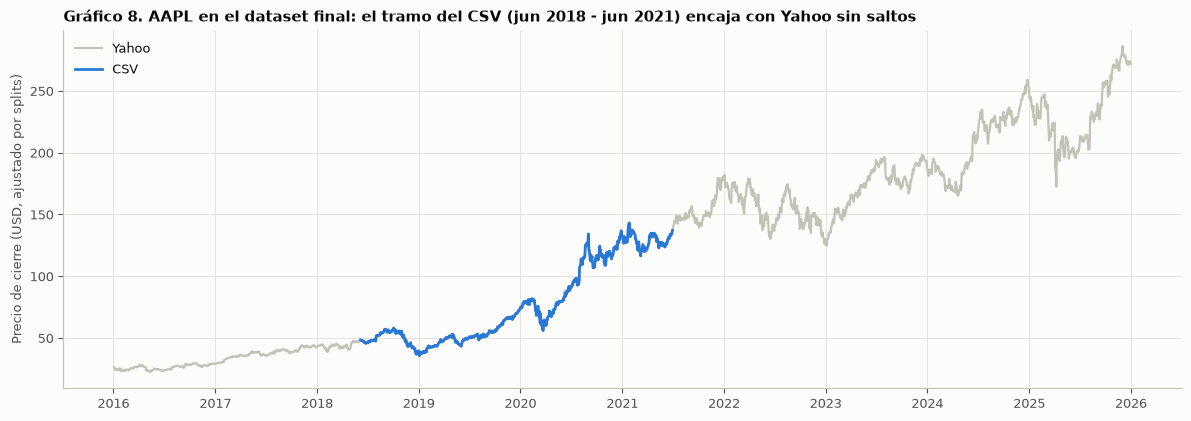

In [132]:
print("df_final:", df_final.shape)
print("Nulos por columna:\n", df_final[columnas].isna().sum().to_string())
print("Velas incoherentes:", contar_incoherencias(df_final))
print("Duplicados symbol+date:", df_final.duplicated(subset=["symbol", "date"]).sum())

procedencia = df_final.groupby("symbol").agg(
    desde=("date", "min"), hasta=("date", "max"), dias=("date", "size"),
    dias_csv=("fuente", lambda s: (s == "csv").sum()),
    vol_imputado=("volume_imputado", "sum"),
)
procedencia["pct_csv"] = (procedencia["dias_csv"] / procedencia["dias"] * 100).round(1)
print(procedencia)
print("Total:", procedencia[["dias", "dias_csv", "vol_imputado"]].sum().to_dict())

# Continuidad en las fronteras CSV <-> Yahoo: un ajuste mal hecho daría retornos enormes ahí
log_ret = np.log(df_final["close"]).groupby(df_final["symbol"]).diff()
cambio_fuente = df_final["fuente"] != df_final.groupby("symbol")["fuente"].shift()
frontera = cambio_fuente & log_ret.notna()
pos_max = log_ret[frontera].abs().idxmax()
print(f"Fronteras CSV <-> Yahoo: {frontera.sum()} | |retorno log| máximo en frontera: {abs(log_ret[pos_max]):.4f}"
      f" ({df_final.loc[pos_max, 'symbol']} {df_final.loc[pos_max, 'date']:%d/%m/%Y}, retorno {log_ret[pos_max]:.4f})"
      f" | en toda la serie: {log_ret.abs().max():.4f}")
# El mayor salto en una frontera, ¿es real? Mismo día solo con Yahoo
yahoo_orden = yahoo.sort_values(["symbol", "date"])
ret_yahoo = np.log(yahoo_orden["close"]).groupby(yahoo_orden["symbol"]).diff()
fila_max = df_final.loc[pos_max]
print(f"Ese mismo día solo con Yahoo: "
      f"{ret_yahoo[(yahoo_orden['symbol'] == fila_max['symbol']) & (yahoo_orden['date'] == fila_max['date'])].iloc[0]:.4f}")
top = df_final.assign(log_ret=log_ret).loc[log_ret.abs().nlargest(5).index, ["symbol", "date", "close", "fuente", "log_ret"]]
print(top.round({"close": 2, "log_ret": 4}).to_string())

# ¿Cuánto cambia la σ de toda la ventana por usar el CSV donde lo hay, en vez de solo Yahoo?
dif_sigma = (sigma_anual(df_final[["symbol", "date", "close"]]) - sigma_anual(yahoo[["symbol", "date", "close"]])).abs()
print(f"\nσ anual 2016-2025, dataset final frente a solo Yahoo: diferencia media {dif_sigma.mean():.3f} pp"
      f" | máxima {dif_sigma.max():.3f} pp ({dif_sigma.idxmax()})")

# Gráfico: AAPL 2016-2025 con el tramo que aporta el CSV destacado
aapl_final = df_final[df_final["symbol"] == "AAPL"].set_index("date")
fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(aapl_final.index, aapl_final["close"], color="#c3c2b7", lw=1.6, label="Yahoo")
ax.plot(aapl_final.index, aapl_final["close"].where(aapl_final["fuente"] == "csv"), color=AZUL, lw=2, label="CSV")
ax.set_ylabel("Precio de cierre (USD, ajustado por splits)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left")
ax.set_title("Gráfico 8. AAPL en el dataset final: el tramo del CSV (jun 2018 - jun 2021) encaja con Yahoo sin saltos")
plt.tight_layout()
plt.show()

# 14. Guardado (Datos/ no se sube al repositorio)

In [133]:
os.makedirs(RUTA_TRANSFORMADOS, exist_ok=True)
df_final.to_csv(f"{RUTA_TRANSFORMADOS}/dowjones_diario_2016_2025.csv", index=False)
print("Guardado dowjones_diario_2016_2025.csv:", df_final.shape)

Guardado dowjones_diario_2016_2025.csv: (64557, 9)


# Explicación de la limpieza

**Objetivo:** un dataset diario, limpio y sin huecos de las 26 empresas del Dow Jones que vienen en los CSV (marketstack), para la ventana 2016-2025. Es la base para calibrar la volatilidad (σ) y las correlaciones (ρ) del Montecarlo de la call asiática. Criterio: **el CSV manda siempre que su dato sea fiable** y **Yahoo Finance solo imputa** lo que el CSV no tiene o no es fiable.

**Resultado:** `Datos/Transformados/dowjones_diario_2016_2025.csv`, con **64.557 filas × 9 columnas** (`symbol, date, open, high, low, close, volume, fuente, volume_imputado`), sin nulos, sin duplicados y sin velas incoherentes. 25 empresas tienen los 2.514 días de mercado de 2016-2025 y DOW 1.707 (cotiza desde el 20/03/2019). **9.961 filas salen del CSV**: el 30,5 % de los días en AAPL, CAT, GS, INTC, NKE y V; el 10,6-10,7 % en el resto; el 15,8 % en DOW. Las demás salen de Yahoo.

---

## 1. Cómo es el CSV (lo que hay que saber antes de tocarlo)

Son 2.744.418 filas intradía, todas de IEX (`exchange = IEXG`), una bolsa pequeña. Los missings no son aleatorios: `last` falta en el 31,0 % de las filas, `close` en el 22,3 % y `volume` en el 30,9 %, pero por bloques. Es así porque **el CSV mezcla tres tipos de fila**:

| Tipo de fila | Cómo se reconoce | Qué significa cada columna | Hora |
|---|---|---|---|
| **Barra** | sin `last` | `open/high/low/close` de una barra de 1 a 30 minutos; sin volumen | **desplazada**: la sesión 09:30-16:00 aparece de 13:30 a 20:00 en verano y de 14:30 a 21:00 en invierno |
| **Instantánea** | con `last`, antes de las 20:00 | `last` = precio en ese momento; **`close` = cierre oficial del día anterior**; `open` = apertura del día; `high/low` = extremos acumulados del día en IEX; `volume` = acumulado **solo de IEX** | correcta |
| **Fila resumen** | con `last`, última fila del día, a las 20:00 (verano) o a las 21:00 (invierno) | **vela oficial del día**: `last` = cierre oficial y `volume` = volumen consolidado de todas las bolsas | — |

Por tramos: de junio de 2018 a mayo de 2020 solo hay barras, y solo de AAPL, CAT, GS, INTC, NKE y V. Desde el 29/05/2020 están las 26 empresas, con instantáneas y barras mezcladas. La fila resumen existe en el 80-100 % de los días de junio de 2020 a febrero de 2021 y desaparece desde marzo de 2021. Todos los ficheros acaban el 30/06/2021.

---

## 2. Hallazgos: dónde se ve y cómo lo vimos

Cada uno está marcado en el código con su número.

| # | Fuente | Hallazgo | Dónde se ve | Cómo lo vimos |
|---|---|---|---|---|
| H1 | CSV | Los ficheros no vienen ordenados: van por bloques en orden descendente | `head()` de AAPL: empieza el 16/08/2018 21:30 y va hacia atrás | Contando las filas en las que la fecha retrocede (99,9 %) |
| H2 | CSV | En las filas con `last`, `close` es el cierre oficial del día anterior; de ahí el 27,7 % de `close` fuera de [`low`, `high`] | CRM 26/08/2020: `close` = 216,05 todo el día mientras `last` va de 246 a 277 | Buscando con el código el día de más rango de CRM y mirándolo fila a fila (gráfico 1) |
| H3 | CSV | `open` es la apertura del día; `high/low` y `volume` son acumulados | Misma tabla de CRM; el volumen crece o se mantiene en el 99,98 % de los minutos | Leyendo la tabla y comprobándolo en todo el dataset |
| H4 | CSV | Tras las 16:00 llegan precios after-hours; la última fila del día vuelve al cierre oficial | CRM 25/08/2020: sube a 241 tras los resultados; a las 20:00, `last` = 216,05 y un volumen 50 veces mayor | Tabla del 25/08 desde las 15:55 y gráfico 1 |
| H5 | CSV | Las filas sin `last` son barras con la hora desplazada 4 h (verano) o 5 h (invierno) | AMGN 15/06/2020: la barra de las "18:05" repite el `last` de las 14:05 (219,54) | Gráfico 2 (misma forma, 4 h más tarde) y horario de las barras en todo el dataset |
| H6 | Yahoo | Sin nulos, duplicados, volúmenes 0 ni velas incoherentes; calendario de la bolsa de Nueva York | Sin datos el 05/12/2018 ni el 09/01/2025 (cierres por los funerales de Bush y Carter) | Con los mismos controles que al CSV |
| H7 | Yahoo | DOW empieza el 20/03/2019 (escisión de DowDuPont) y sus primeros días tienen poco volumen | Volumen mediano de 1,30 M del 20 al 29/03/2019 frente a 6,68 M en abril | `min()` por empresa y sus primeras filas |
| H8 | CSV | La fila resumen es el cierre oficial: coincide con el `close` del día siguiente | CRM 25/08/2020 20:00 → 216,05 = `close` del 26/08; igual en el 99,44 % de 4.649 días | Comparando las dos en todos los días |
| H9 | CSV | Donde no coinciden (26 días de AXP, CVX y DIS en julio de 2020), el bueno es el `close` del día siguiente | AXP 09/07/2020: resumen 90,60, `close` del día siguiente 90,57, Yahoo 90,57 | Contrastando esos 26 días con Yahoo (26 de 26) |
| H10 | CSV | 9 filas resumen traen `open = high = low`: vela rota, aunque su cierre es bueno | AAPL e INTC entre el 29/05 y el 08/06/2020 | Al revisar la coherencia de las filas resumen (8 incoherentes, todas así) |
| H11 | CSV | La fila resumen desaparece desde marzo de 2021 | Del 80-100 % de los días a un 18,7 % en marzo y ~0 % después | Tabla por mes y gráfico 3 |
| H12 | CSV | Hay días incompletos: los datos se cortan a media sesión | 02/06/2020 (20 empresas, hasta las 12:24-12:28) y 29/03/2021 (26, último `last` como muy tarde a las 11:18) | Hora de la primera y la última fila de cada día; errores de hasta el 1,7 % al validar |
| H13 | CSV | Los precios no están ajustados por splits | AAPL pasa de ~500 $ a ~125 $ el 31/08/2020 (split 4:1) | Gráfico 4 |
| H14 | Yahoo | `Close` ya viene ajustado por splits incluso con `auto_adjust=False`; los spin-offs cuentan como split; el volumen lleva el ajuste inverso | `close_CSV / close_Yahoo` = 4,000 (AAPL), 1,046 (IBM), 1,196 (MMM), 1,048 (MRK) | Tabla de cocientes frente al factor de cada fecha y gráfico 4 |
| H15 | — | El cierre oficial del CSV coincide con Yahoo; el último precio de la sesión, casi | Error medio 0,000 % frente a 0,032 % | Comparando cada cierre del CSV con el de Yahoo |
| H16 | CSV | Cuando el cierre sale de las barras, la de las 16:00 (un único precio en el 98,8 % de los casos) a veces no es el cierre oficial | Resultados de INTC (24/10/2019, 23/01/2020, 23/04/2020), *ticks* erróneos el 18/03/2020 (INTC, AAPL) y GS 11/06/2020 | Gráfico 5 (los puntos que quedan) y gráfico 6 (barras de esos días) |
| H17 | CSV | Sin fila resumen, `open` es la primera operación en IEX, no la apertura oficial | Error medio del 0,20 % en `open` y del 0,05 % en `high/low` | Comparando `open/high/low` con Yahoo |
| H18 | CSV | El volumen intradía es solo el de IEX (~3 %); el consolidado solo viene en la fila resumen | Cociente CSV/Yahoo ≈ 1 con resumen y 0,01-0,035 sin él | Tabla por mes y gráfico 7 (dos nubes separadas) |
| H19 | CSV | En 52 velas el cierre oficial cae fuera del `high/low` de IEX | Todas tienen cierre del día siguiente y `open/high/low` de la sesión | Comprobación de coherencia OHLC |
| H20 | CSV | Hay barras en 19 festivos para las 6 empresas del tramo 2018-2020 (114 filas-día) | 04/07, Acción de Gracias, Navidad, 05/12/2018… Barras planas: un solo precio en todo el día | Cruzando con el calendario de Yahoo |
| H21 | CSV | Faltan días de mercado enteros | 58 días-empresa: 3, 10, 11 y 12 de junio de 2020 | Cruzando el calendario de Yahoo con los días de cada empresa |

---

## 3. Decisiones y su porqué

1. **Días con la fecha de Nueva York, no UTC.** Con UTC, lo del viernes por la tarde cae en sábado (13.702 filas en fin de semana); con la hora de Nueva York quedan 0.
2. **Hora de las barras corregida** (se le resta el desfase de 4 o 5 h). Si no, la sesión real no se puede recortar y las barras se mezclan con las instantáneas en otro orden.
3. **Vela diaria del CSV:**
   - **Cierre**: el cierre oficial. Primero el `close` del día de mercado siguiente, que acierta incluso donde la fila resumen falla (H9), y si no hay, el `last` de la fila resumen. Solo si no existe ninguno de los dos, el último precio de la sesión (09:30-16:00).
   - **open/high/low y volumen**: los de la fila resumen, que son los oficiales. Sin resumen, o con resumen roto (H10), `open/high/low` salen solo de la sesión real, sin pre-market ni after-hours.
   - *Por qué*: frente a la regla inicial (último `last` hasta las 16:00), el error del cierre respecto a Yahoo baja de **0,079 % a 0,010 %** de media y los días con error > 1 % pasan de **48 a 6**. En la σ anual del tramo del CSV (jun 2020-jun 2021), la desviación frente a Yahoo baja de 0,20 a 0,03 puntos de media (máxima de 0,73 en DOW a 0,41 en GS). No usamos "el último `last` del día" porque metería precios after-hours (H4): un solo cierre malo mete dos retornos falsos (ida y vuelta) e infla σ.
4. **Días incompletos (50) → fila entera de Yahoo.** Si los datos se cortan a media sesión, la vela no representa el día: su cierre llega a desviarse un 1,7 % y el `high/low` es parcial. Criterio: sin fila resumen y con la sesión empezando después de las 10:00 o acabando antes de las 15:30, o con el cierre tomado antes de las 15:30. Es un criterio interno del CSV, no depende de Yahoo.
5. **Los 6 cierres con after-hours o *ticks* erróneos (H16) se mantienen** porque el CSV manda. Quedan como pendientes (sección 6).
6. **Splits: el CSV se ajusta a la escala de Yahoo** (precios ÷ factor, volumen × factor) y no al revés. La mayor parte de 2016-2025 viene de Yahoo y, si no, cada frontera CSV↔Yahoo tendría un escalón falso. Además, el split de AAPL cae dentro del propio CSV: sin ajustar, ese día daría un retorno de ln(1/4) ≈ −1,39. Dividir la serie anterior por una constante no cambia ningún retorno real. Se ajustan 1.374 filas.
7. **Volumen: si el del CSV es menor que el 50 % del de Yahoo, se imputa desde Yahoo** (2.213 de 6.905). No es un missing, es otra variable (el volumen de IEX): mantenerlo haría caer la serie ×30 sin motivo. El umbral separa sin ambigüedad: por debajo de 0,3 hay 2.213 días (todos sin fila resumen), entre 0,3 y 0,5 ninguno y por encima de 0,5 los 4.692 con resumen. Es una excepción al criterio de que el CSV manda, pero no afecta a la valoración, porque el Montecarlo solo usa `close`.
8. **Coherencia OHLC: se amplía el rango en vez de borrar filas** (`high = max(high, open, close)`, `low = min(low, open, close)`). En las 52 velas incoherentes el error está en los extremos de IEX, no en el cierre oficial.
9. **Calendario = días de mercado de Yahoo.** Se eliminan las 114 filas-día de festivos (barras planas): meterían retornos 0 falsos y bajarían σ.
10. **Si el CSV no tiene el día (58), no tiene cierre (52) o el día está incompleto (50), la fila entera viene de Yahoo.** Así no se mezcla en una misma vela el OHLC de una fuente con el cierre de otra. Si el CSV tiene la vela pero le falta el volumen (5.269 días), solo se imputa el volumen (`volume_imputado = True`).

---

## 4. Comprobaciones del resultado

- **Cierre del CSV frente a Yahoo** (días completos):

  | Origen | Días | Error medio | Días > 1 % |
  |---|---|---|---|
  | `close` del día siguiente | 6.814 | 0,000 % (máx. 0,073 %) | 0 |
  | `last` de la fila resumen | 43 | 0,000 % | 0 |
  | Último precio de la sesión | 3.104 | 0,032 % | 6 |

  Ningún día pasa del 5 %. Los días incompletos, que van a Yahoo, tenían un error medio del 0,60 %.
- **open/high/low**: con fila resumen el error es ~0 %. Desde la sesión, 0,20 % en `open` y 0,05 % en `high/low` (H17). No afecta al Montecarlo.
- **Efecto en σ de usar el CSV**: en la σ anual 2016-2025, el dataset final se desvía de la de solo Yahoo 0,006 puntos de media (máximo 0,03, en V). En el tramo del CSV (jun 2020-jun 2021), 0,03 de media.
- **Continuidad en las 250 fronteras CSV↔Yahoo:** el mayor salto es el de BA el 11/06/2020 (−0,180), y es real: con solo Yahoo da −0,179. Si el ajuste de splits fallara, en AAPL aparecería un −1,39. Los mayores retornos de toda la serie también son reales y salen de Yahoo: INTC 02/08/2024 (−0,30, resultados), BA 16/03/2020 y CVX 18/03/2020 (COVID), UNH 17/04/2025 y DOW 09/03/2020.
- El gráfico 8 (AAPL 2016-2025) muestra que el tramo del CSV encaja con Yahoo sin saltos, también en el split.

---

## 5. Qué cambia respecto a la primera versión (prueba.ipynb)

| Antes | Problema | Ahora |
|---|---|---|
| Dos tramos: "sin `last`" (2018-2020) y "con `last`" (2020-2021) | Desde junio de 2020 los dos tipos se mezclan en el mismo día y las barras tienen la hora desplazada (H5) | Tres tipos de fila, con la hora de las barras corregida |
| Cierre = último `last` hasta las 16:00 | No es el cierre oficial: 48 días con error > 1 % | Cierre oficial del propio CSV (H8, H9): 6 días > 1 % |
| `open/high/low` = primero, máximo y mínimo del día entero | Incluía pre-market y after-hours: errores de hasta el 17,8 % en `open` y el 10,6 % en `high` | Los de la fila resumen o los de la sesión real |
| Volumen: "desde marzo de 2021 el CSV da solo el volumen de IEX" | El volumen intradía siempre fue solo de IEX; lo que desaparece en marzo de 2021 es la fila resumen (H11, H18) | La misma regla (umbral del 50 %) con la explicación correcta: antes de marzo de 2021 ya estaban afectados todos los días sin fila resumen |
| "10 días > 2 %, sueltos y sin patrón" | Sí tenían patrón: 5 tenían las instantáneas cortadas a media sesión, 3 eran barras de INTC con precios after-hours o erróneos y en 2 el último precio de IEX antes de las 16:00 se alejaba del cierre oficial | Los 7 que no son de INTC salen ahora con el cierre oficial (iguales a Yahoo); los 3 de INTC siguen entre los 6 pendientes |
| 94 días sin cierre | 42 tenían el cierre oficial en el `close` del día siguiente | 52 días sin cierre |
| — | Los 58 días sin filas se rellenaban con Yahoo sin identificarlos y los 50 incompletos se daban por buenos | Detectados, contados e imputados desde Yahoo |

---

## 6. Pendientes para comentar con los profesores

1. **Los 6 cierres del CSV que se alejan más de un 1 % del oficial** (INTC 18/03/2020, 24/10/2019, 23/01/2020 y 23/04/2020; AAPL 18/03/2020; GS 11/06/2020). Se han mantenido porque el CSV manda, pero sabemos que están mal (H16). ¿Se imputan? En la ventana 2016-2025 apenas cambian σ, pero si se calibra solo con el tramo jun 2020-jun 2021 el de GS, por sí solo, le baja la σ anual de 30,9 % a 30,5 %.
2. **Volumen desde Yahoo cuando el del CSV es solo de IEX**: es una excepción al criterio de que el CSV manda. ¿Es correcto así?
3. **Dividendos:** ni el CSV ni el `Close` de Yahoo están ajustados por dividendos. Para un Montecarlo bajo medida neutral al riesgo lo habitual es usar el precio sin descontar dividendos y tratar la rentabilidad por dividendo aparte, si el enunciado la pide.

---

## 7. Cómo ejecutarlo

- Necesita conexión a Internet (descarga de Yahoo) y tarda unos dos minutos. Se ha probado con Python 3.12, pandas 3.0.5, numpy 2.4.6, matplotlib 3.11 y yfinance 1.7.0.
- Las rutas son relativas al notebook (`Datos/Originales/DowJones/`), y la salida se sobrescribe en cada ejecución. La carpeta `Datos/` no se sube al repositorio.
- Las cifras de este texto son las de la ejecución del 30/09/2026. Si Yahoo revisa algún dato histórico, podrían variar en algún decimal.